# 3. Market basket analysis

Which products are bought together, and how strongly?

Three numbers describe every pair of products:

* **Support**: the share of all orders that contain both.
* **Confidence**: of the orders with the first product, the share that also have the second.
* **Lift**: how many times more often the two appear together than they would by chance. A lift of 1 means no connection.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator
from retail_analysis.clean import SHOPS, load, clean, open_shop
from retail_analysis.segmentation import GROUPS

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black", "axes.edgecolor": "#3a3b3e", "axes.grid": True,
                     "grid.color": "#1c1c1e", "figure.figsize": (11, 4.5), "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
WHITE, SILVER, GREY, JADE, RED = "#f2f2f0", "#d4d6da", "#8d8d90", "#5fd0a0", "#e0787a"
COLORS = dict(zip(GROUPS, ["#7fb4d8", JADE, "#9fd9bd", WHITE, SILVER, "#c9a25a", GREY]))
money = lambda v, _=None: f"£{v:,.0f}"
UK, AMAZON, GROCERY = SHOPS

sales, removed = open_shop(UK)
from retail_analysis.market_basket import pairs, rules, families

found = pairs(sales)
print(f"{len(found):,} pairs of products share at least 30 orders")

20,148 pairs of products share at least 30 orders


## The strongest pairs

In [2]:
show = found.head(12).assign(pair=lambda t: t.name_a.str.title().str.strip() + "  +  " + t.name_b.str.title().str.strip())
show[["pair", "together", "support", "lift"]].style.format({"together": "{:,.0f}", "support": "{:.1%}", "lift": "{:.0f}x"}).hide(axis="index")

pair,together,support,lift
Regency Tea Plate Green + Regency Tea Plate Pink,201,1.1%,61x
Regency Milk Jug Pink + Regency Sugar Bowl Green,205,1.1%,52x
Set Of 3 Wooden Stocking Decoration + Set Of 3 Wooden Tree Decorations,181,1.0%,49x
Regency Tea Plate Roses + Regency Tea Plate Pink,195,1.1%,49x
"Key Fob , Shed + Key Fob , Back Door",165,0.9%,49x
Set/10 Pink Polkadot Party Candles + Set/10 Blue Polkadot Party Candles,180,1.0%,48x
Set Of 3 Wooden Sleigh Decorations + Set Of 3 Wooden Tree Decorations,161,0.9%,48x
Regency Tea Plate Roses + Regency Tea Plate Green,227,1.2%,47x
Poppy'S Playhouse Bedroom + Poppy'S Playhouse Livingroom,203,1.1%,47x
Set/6 Red Spotty Paper Plates + Set/6 Red Spotty Paper Cups,236,1.3%,47x


## Rules: customers who buy this also buy that

A pair reads differently in each direction, so each pair gives two rules. These are the most reliable ones.

In [3]:
both_ways = rules(found)
both_ways.head(12).assign(buys=lambda t: t.buys.str.title(), also_buys=lambda t: t.also_buys.str.title()).style.format({"together": "{:,.0f}", "support": "{:.1%}", "confidence": "{:.0%}", "lift": "{:.0f}x"}).hide(axis="index")

buys,also_buys,together,support,confidence,lift
Regency Tea Plate Pink,Regency Tea Plate Green,201,1.1%,90%,61x
Regency Tea Plate Pink,Regency Tea Plate Roses,195,1.1%,87%,49x
Poppy'S Playhouse Livingroom,Poppy'S Playhouse Kitchen,214,1.2%,86%,46x
Regency Tea Plate Green,Regency Tea Plate Roses,227,1.2%,84%,47x
Set/6 Red Spotty Paper Cups,Set/6 Red Spotty Paper Plates,236,1.3%,83%,47x
Pink Regency Teacup And Saucer,Green Regency Teacup And Saucer,454,2.5%,83%,22x
Wooden Tree Christmas Scandinavian,Wooden Star Christmas Scandinavian,226,1.2%,82%,35x
Poppy'S Playhouse Livingroom,Poppy'S Playhouse Bedroom,203,1.1%,81%,47x
Poppy'S Playhouse Bedroom,Poppy'S Playhouse Kitchen,252,1.4%,80%,43x
Set/10 Blue Polkadot Party Candles,Set/10 Pink Polkadot Party Candles,180,1.0%,80%,48x


Nine in ten orders with the pink tea plate also have the green one.

## Every pair at once

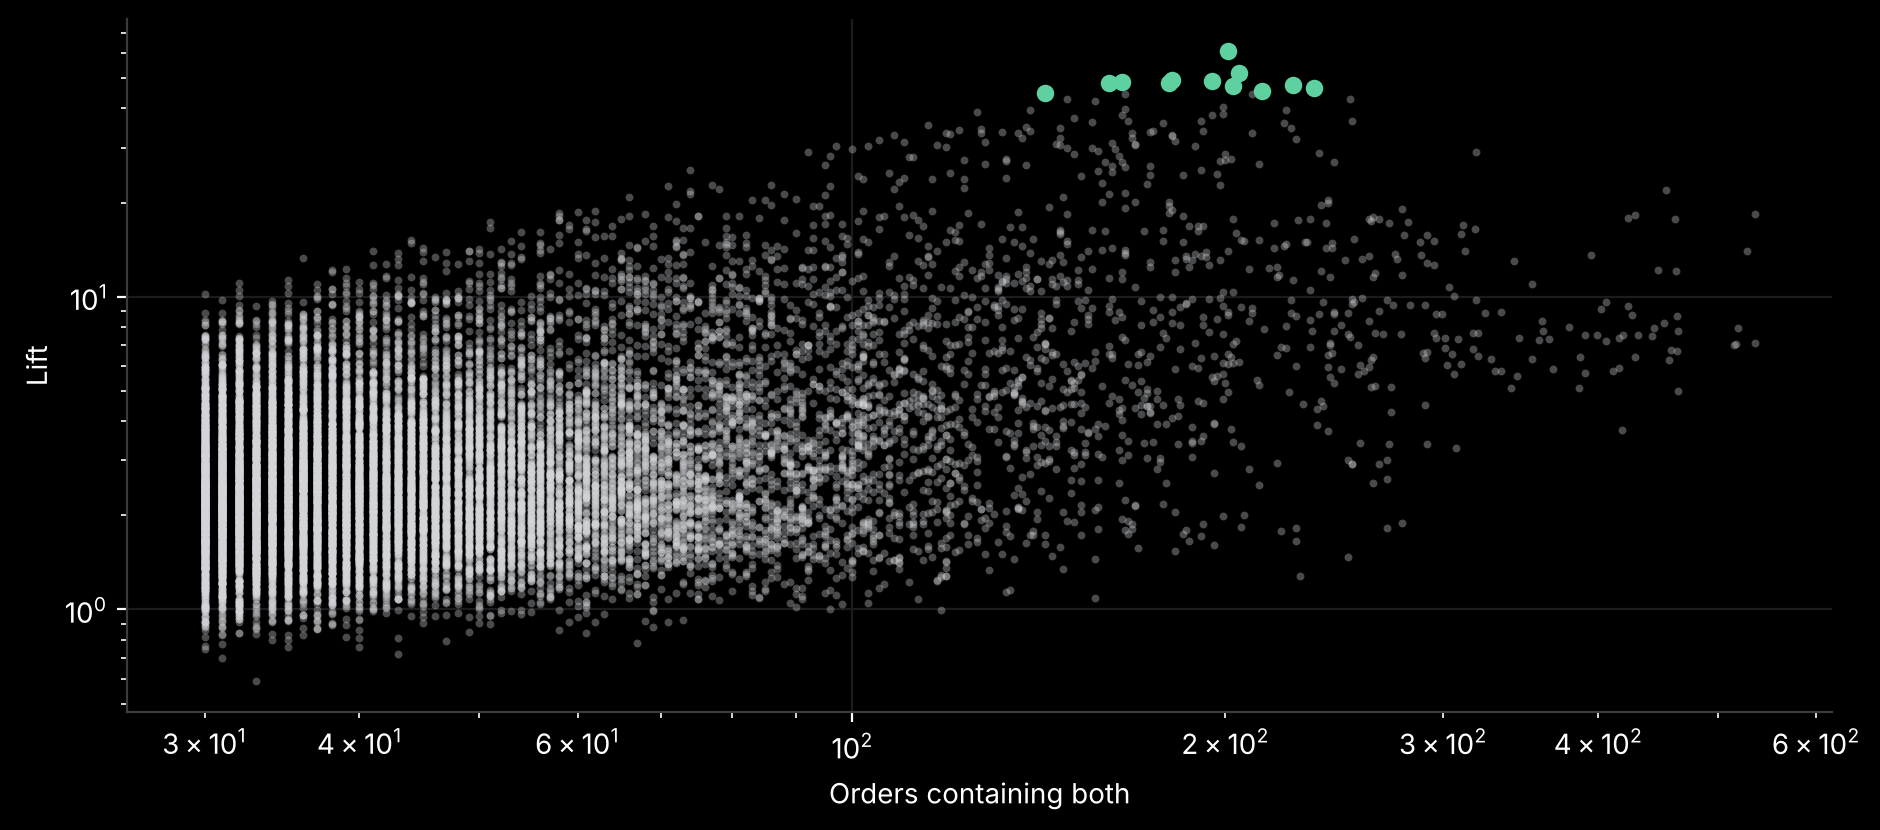

In [4]:
fig, ax = plt.subplots()
ax.scatter(found.together, found.lift, s=8, color=SILVER, alpha=0.35, linewidths=0)
ax.scatter(found.head(12).together, found.head(12).lift, s=28, color=JADE)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Orders containing both"); ax.set_ylabel("Lift")
plt.show()

Up and to the right is where a shop wants to look: pairs bought together often and far more than chance. The green dots are the twelve from the table.

One caution on reading lift. This shop has some very large orders, and a large order holds many products, so two unrelated products already show a lift of about 2. The pairs worth acting on sit far above that.

## Product families

Join products by their 150 strongest pairs and they fall into families: groups that sell together, directly or through each other. Each family is a ready made bundle. Each cluster is named after its most connected product, with the number of products in it.

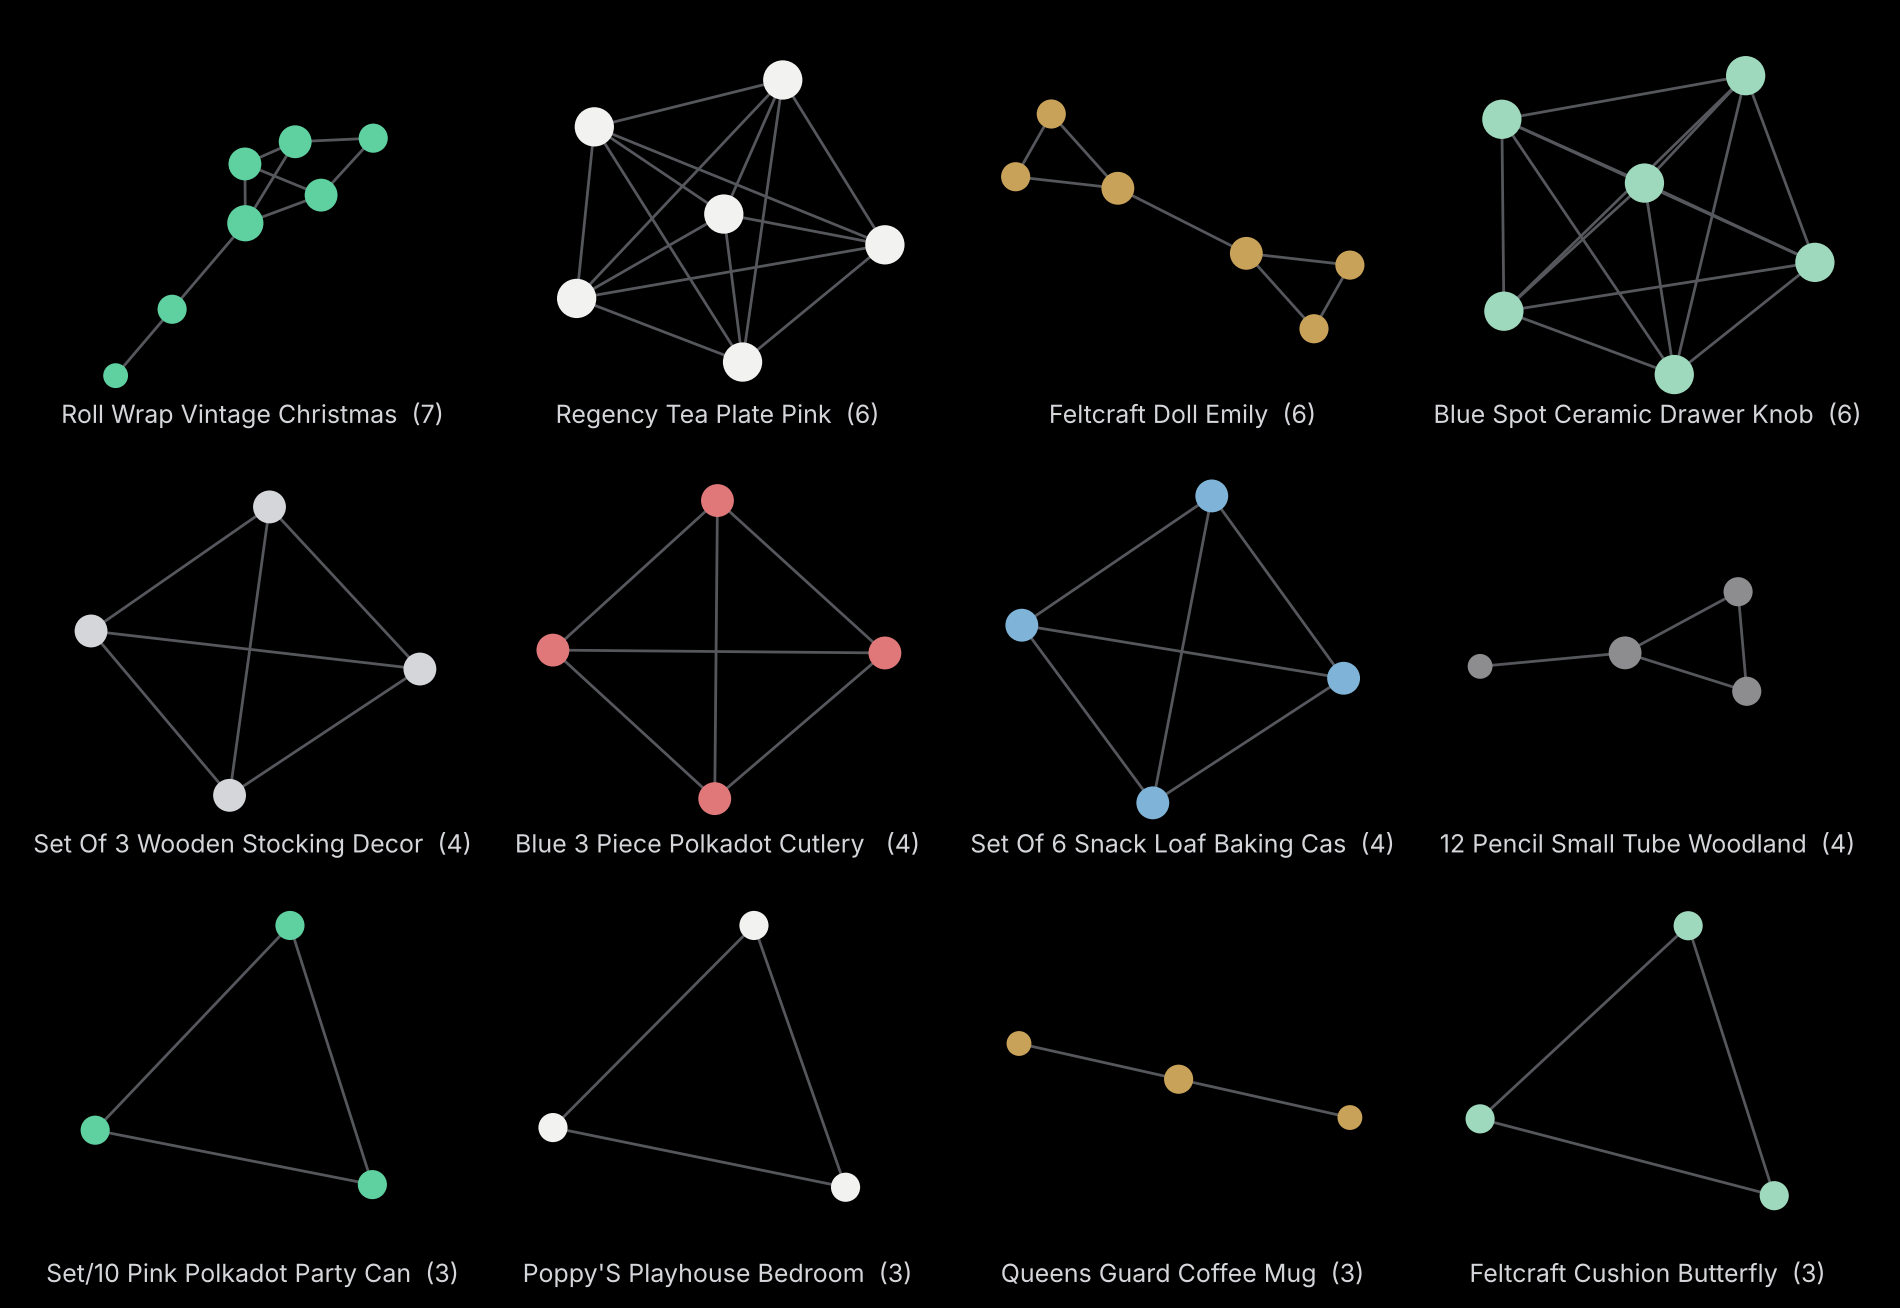

In [5]:
def draw_families(found, ax, strongest=150, biggest=12, across=4):
    """Products as dots, strong pairs as lines, one cluster per family. Returns the families."""
    spots = families(found, strongest, biggest, across).set_index("name")
    palette = [JADE, WHITE, "#c9a25a", "#9fd9bd", SILVER, "#e0787a", "#7fb4d8", GREY]
    for a, b in zip(found.head(strongest).name_a, found.head(strongest).name_b):
        if a in spots.index:
            ax.plot(*zip(spots.loc[a, ["x", "y"]], spots.loc[b, ["x", "y"]]), color="#55575c", lw=1, zorder=1)
    ax.scatter(spots.x, spots.y, s=50 + 30 * spots.links, color=[palette[(f - 1) % 8] for f in spots.family], zorder=2, linewidths=0)
    for number, members in spots.groupby("family"):
        words = members.index[0].title().split()                       # name the family after its busiest product
        ax.text((number - 1) % across, -((number - 1) // across) - 0.47, " ".join(words)[:30] + f"  ({len(members)})", ha="center", fontsize=9, color=SILVER)
    ax.set_xlim(-0.5, across - 0.5); ax.axis("off")
    return spots

fig, ax = plt.subplots(figsize=(12, 8))
spots = draw_families(found, ax)
plt.show()

In [6]:
listed = spots.reset_index().groupby("family")["name"].agg(products="size", members=lambda n: ", ".join(n.str.title().str.strip()))
listed.head(8).style.set_properties(subset=["members"], **{"text-align": "left", "white-space": "normal"})

,products,members
family,,
1,7,"Roll Wrap Vintage Christmas, Roll Wrap 50'S Christmas, Roll Wrap Vintage Spot, 6 Gift Tags Vintage Christmas, Box Of 6 Mini Vintage Crackers, 6 Gift Tags 50'S Christmas, Box Of 6 Mini 50'S Crackers"
2,6,"Regency Tea Plate Pink, Regency Sugar Bowl Green, Regency Teapot Roses, Regency Tea Plate Green, Regency Milk Jug Pink, Regency Tea Plate Roses"
3,6,"Feltcraft Doll Emily, Feltcraft Princess Olivia Doll, Feltcraft Princess Charlotte Doll, Feltcraft Doll Rosie, Feltcraft Princess Lola Doll, Feltcraft Doll Molly"
4,6,"Blue Spot Ceramic Drawer Knob, Blue Stripe Ceramic Drawer Knob, Red Stripe Ceramic Drawer Knob, Red Spot Ceramic Drawer Knob, White Spot Red Ceramic Drawer Knob, White Spot Blue Ceramic Drawer Knob"
5,4,"Set Of 3 Wooden Stocking Decoration, Set Of 3 Wooden Tree Decorations, Set Of 3 Wooden Heart Decorations, Set Of 3 Wooden Sleigh Decorations"
6,4,"Blue 3 Piece Polkadot Cutlery Set, Red 3 Piece Retrospot Cutlery Set, Pink 3 Piece Polkadot Cutlery Set, Green 3 Piece Polkadot Cutlery Set"
7,4,"Set Of 6 Snack Loaf Baking Cases, Set Of 12 Fairy Cake Baking Cases, Set Of 12 Mini Loaf Baking Cases, Set Of 6 Tea Time Baking Cases"
8,4,"12 Pencil Small Tube Woodland, 12 Pencils Small Tube Skull, 12 Pencils Small Tube Red Retrospot, Set 12 Colour Pencils Spaceboy"


## What this says

* **The strongest links are sets sold as separate items.** Tea plates in three colors, a milk jug and a sugar bowl, matching decorations. A buyer of one is around fifty times more likely than chance to buy the other.
* **The rules are reliable enough to act on.** For the best ones, eight or nine orders in ten with the first product include the second.
* **The families are bundles the shop is not selling as bundles.** Each one could be a single listing, a suggestion at checkout, or a reason to restock the pieces together.

Notebook 4 checks whether these links held up on later sales.